# 8. Wielorozdzielcza analiza falkowa

**Arkadiusz Liber** · *Falki w praktyce. Od wzoru do kodu*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/blob/main/rozdzial-08.ipynb)

Notatnik do książki. Zawiera wszystkie programy z tekstu rozdziału oraz ćwiczenia z rozwiązaniami.

Notatnik działa lokalnie (Jupyter) i w Google Colab. Komórki można uruchamiać po kolei poleceniem *Uruchom wszystko*.

In [1]:
# Uruchom tę komórkę jako pierwszą (lokalnie albo w Google Colab).
import sys, subprocess, importlib.util, os
if importlib.util.find_spec("pywt") is None:      # PyWavelets
    subprocess.check_call([sys.executable, "-m", "pip",
                           "install", "-q", "PyWavelets"])
import numpy as np
import matplotlib.pyplot as plt
import pywt

SZARY, NIEBIESKI, RDZAWY, ZIELONY = "#757575", "#1273E2", "#D93B0B", "#078832"
FIOLET, BURSZTYN = "#9258D5", "#B36000"
plt.rcParams.update({
    "text.color": SZARY, "axes.labelcolor": SZARY, "axes.edgecolor": SZARY,
    "xtick.color": SZARY, "ytick.color": SZARY, "axes.titlecolor": SZARY,
    "font.size": 10, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False})


## Programy z tekstu rozdziału

### Kod 8.1. Rzuty na przestrzenie Haara: zawieranie i malejący błąd

In [2]:
import numpy as np

N = 1024
x = (np.arange(N) + 0.5)/N
f = np.sin(2*np.pi*x) + 0.5*np.sin(2*np.pi*5*x**2)

def rzut(f, j):
    """Rzut na przestrzeń funkcji stałych na 2**j próbkach."""
    m = 2**j
    return np.repeat(f.reshape(-1, m).mean(axis=1), m)

for j in (7, 5, 3, 1):
    blad = np.linalg.norm(f - rzut(f, j))/np.linalg.norm(f)
    print(f"j = {j}: odcinków {N//2**j:4d}, błąd {100*blad:6.2f}%")

# zawieranie: rzut na przestrzeń zgrubniejszą można wykonać
# w dwóch krokach
print(np.allclose(rzut(rzut(f, 3), 5), rzut(f, 5)))
# reszta jest ortogonalna do przybliżenia
print(np.isclose(np.dot(f - rzut(f, 5), rzut(f, 5)), 0))

j = 7: odcinków    8, błąd  40.75%
j = 5: odcinków   32, błąd  14.15%
j = 3: odcinków  128, błąd   3.63%
j = 1: odcinków  512, błąd   0.79%
True
True


### Kod 8.2. Algorytm kaskadowy i sprawdzenie równania dwuskalowego

In [3]:
import numpy as np
import pywt

def kaskada(h, kroki):
    """Wartości funkcji skalującej w punktach n / 2**kroki."""
    phi = np.array([1.0])
    for _ in range(kroki):
        rozszerzona = np.zeros(2*len(phi))
        rozszerzona[::2] = phi                    # ekspansja
        phi = np.convolve(rozszerzona, np.sqrt(2)*h)
    return np.concatenate([[0.0], phi])           # phi(0) = 0

w = pywt.Wavelet("db4")
h = np.array(w.rec_lo)
m = 8
phi = kaskada(h, m)
krok = 2.0**-m
print("całka:", round(np.sum(phi)*krok, 6))                 # (8.1)
print("norma:", round(np.sqrt(np.sum(phi**2)*krok), 6))

# porównanie z funkcją biblioteczną
phi_pywt, psi_pywt, x = w.wavefun(level=m)
n = min(len(phi), len(phi_pywt))
print("różnica:", np.max(np.abs(phi[:n] - phi_pywt[:n])))

# równanie dwuskalowe (8.4) na siatce o kroku 2**-m
def phi_w(i):                     # wartość phi w punkcie i*krok
    return phi[i] if 0 <= i < len(phi) else 0.0
punkty = range((len(h) - 1)*2**m)
lewa = np.array([phi_w(i) for i in punkty])
prawa = np.array([np.sqrt(2)*sum(h[k]*phi_w(2*i - k*2**m)
                                 for k in range(len(h)))
                  for i in punkty])
print("równanie dwuskalowe:", np.max(np.abs(lewa - prawa)))

całka: 1.0
norma: 1.0
różnica: 1.1102230246251565e-15
równanie dwuskalowe: 3.6805081746173196e-05


### Kod 8.3. Rozkład wielorozdzielczy: składowe w przestrzeniach V i W

In [4]:
import numpy as np
import pywt

x = np.linspace(0, 1, 1024, endpoint=False)
f = (np.sin(2*np.pi*x)                                   # wolna fala
     + 0.3*np.sin(2*np.pi*40*x)*np.exp(-((x - 0.7)/0.08)**2)
     + 0.5*((x > 0.25) & (x < 0.4)))                     # dwa skoki

J, falka = 4, "db4"
wsp = pywt.wavedec(f, falka, level=J, mode="periodization")

def skladowa(i):
    """Część sygnału odtworzona z jednego zestawu współczynników."""
    w = [c if k == i else np.zeros_like(c) for k, c in enumerate(wsp)]
    return pywt.waverec(w, falka, mode="periodization")

A = skladowa(0)                                 # rzut na V_J
D = {J - i + 1: skladowa(i) for i in range(1, J + 1)}   # rzuty na W_j

print(np.allclose(A + sum(D.values()), f))      # wzór (8.8)
print("A4·D4 =", round(float(A @ D[4]), 10),
      " D4·D2 =", round(float(D[4] @ D[2]), 10))
for j in range(J, 0, -1):                       # kolejne przybliżenia
    A = A + D[j]                                # wzór (8.12)
    blad = np.linalg.norm(f - A)/np.linalg.norm(f)
    print(f"przybliżenie w V_{j - 1}: błąd {100*blad:.3f}%")

True
A4·D4 = -0.0  D4·D2 = -0.0
przybliżenie w V_3: błąd 2.768%
przybliżenie w V_2: błąd 1.483%
przybliżenie w V_1: błąd 1.116%
przybliżenie w V_0: błąd 0.000%


### Kod 8.4. Ciągła transformata falkowa z falką Haara i jej związek z pochodną

In [5]:
import numpy as np

x = np.linspace(-np.pi, np.pi, 2048, endpoint=False)
dx = x[1] - x[0]
f = np.sin(x)*np.sin(x**2)

def cwt_haar(f, a):
    """W(a, b) dla skali a (parzysta liczba próbek) i b = x[n]."""
    S = np.concatenate([[0.0], np.cumsum(f)])
    n = np.arange(len(f) - a)
    pierwsza = S[n + a//2] - S[n]            # suma na pierwszej połowie
    druga = S[n + a] - S[n + a//2]           # suma na drugiej połowie
    return (pierwsza - druga)*dx/np.sqrt(a*dx)

pochodna = np.cos(x)*np.sin(x**2) + 2*x*np.sin(x)*np.cos(x**2)
for a in (2, 30, 200):
    W = cwt_haar(f, a)
    n = np.arange(len(W))
    wzor = -(a*dx)**1.5/4*np.interp(x[n] + a*dx/2, x, pochodna)
    blad = np.linalg.norm(W - wzor)/np.linalg.norm(W)
    print(f"skala {a:3d} próbek: błąd wzoru (8.15) {100*blad:5.1f}%")

skala   2 próbek: błąd wzoru (8.15)   0.7%
skala  30 próbek: błąd wzoru (8.15)   0.8%
skala 200 próbek: błąd wzoru (8.15)  18.2%


### Kod 8.5. Pierwszy poziom dyskretnej transformaty falkowej z falką db2

In [6]:
import numpy as np
import pywt

x = np.linspace(-np.pi, np.pi, 1024, endpoint=False)
f = np.sin(x)*np.sin(x**2)

cA1, cD1 = pywt.dwt(f, "db2", mode="periodization")
print(len(f), len(cA1), len(cD1))
print("max |cA1| =", np.abs(cA1).max().round(3),
      " max |f|·sqrt(2) =", (np.abs(f).max()*np.sqrt(2)).round(3))
srodek = slice(8, -8)                        # bez brzegów
print("max |cD1| =", np.abs(cD1[srodek]).max().round(5))
print("udział energii detali:",
      f"{100*np.sum(cD1[srodek]**2)/np.sum(f**2):.5f}%")

1024 512 512
max |cA1| = 1.353  max |f|·sqrt(2) = 1.353
max |cD1| = 0.00038
udział energii detali: 0.00001%


## Ćwiczenia i rozwiązania

### Ćwiczenie 8.1
Sprawdź, że dla funkcji skalującej Haara wzór (9.5) daje h₀ = h₁ = 1/√2 i zero dla pozostałych n.

### Rozwiązanie 8.1

In [7]:
x = np.linspace(-4, 6, 1000001)
dx = x[1] - x[0]
phi = lambda x: ((x >= 0) & (x < 1)).astype(float)
for n in range(-2, 4):
    h_n = np.sum(phi(x - n)*phi(x/2))*dx/np.sqrt(2)
    print(n, round(h_n, 4))

-2 0.0
-1 0.0
0 0.7071
1 0.7071
2 0.0
3 0.0


### Ćwiczenie 8.2
Wyznacz algorytmem kaskadowym funkcję skalującą filtru h = (1, 2, 1)/(2√2). Jaką znaną funkcję otrzymujesz? Czy jej przesunięcia są ortogonalne?

### Rozwiązanie 8.2

różnica od funkcji trójkątnej: 0.0
iloczyn skalarny z przesunięciem o 1: 0.1667 (teoria: 1/6)


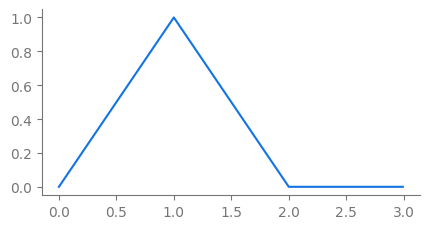

In [8]:
def kaskada(h, kroki):
    phi = np.array([1.0])
    for _ in range(kroki):
        rozszerzona = np.zeros(2*len(phi)); rozszerzona[::2] = phi
        phi = np.convolve(rozszerzona, np.sqrt(2)*h)
    return np.concatenate([[0.0], phi])
m = 8
h = np.array([1, 2, 1])/(2*np.sqrt(2))
phi = kaskada(h, m)
xs = np.arange(len(phi))/2**m
trojkat = np.clip(1 - np.abs(xs - 1), 0, None)
print("różnica od funkcji trójkątnej:", np.abs(phi - trojkat).max().round(4))
przes = 2**m
print("iloczyn skalarny z przesunięciem o 1:",
      round(np.sum(phi[przes:]*phi[:-przes])/2**m, 4), "(teoria: 1/6)")
fig, ax = plt.subplots(figsize=(4.4, 2.4))
ax.plot(xs, phi, color=NIEBIESKI); plt.tight_layout(); plt.show()

### Ćwiczenie 8.3
Zmodyfikuj kod 8.2 tak, aby wyznaczał również falkę ze wzoru (9.10). Porównaj wynik z `wavefun`.

### Rozwiązanie 8.3

różnica: 0.000136
całka falki: 0.0  norma: 1.0


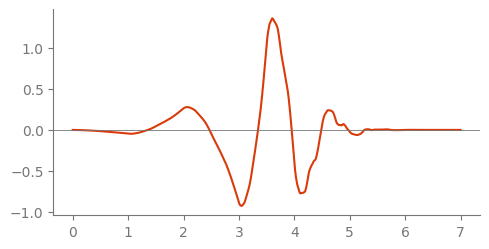

In [9]:
w = pywt.Wavelet("db4")
h, g = np.array(w.rec_lo), np.array(w.rec_hi)
m = 8
phi = kaskada(h, m)                           # phi w punktach i / 2**m
def phi_w(i):
    return phi[i] if 0 <= i < len(phi) else 0.0
# wzór (8.10): psi(x) = sqrt(2) * suma g_n phi(2x - n)
punkty = range((len(h) - 1)*2**m + 1)
psi = np.array([np.sqrt(2)*sum(g[n]*phi_w(2*i - n*2**m)
                               for n in range(len(g))) for i in punkty])
phi_pywt, psi_pywt, x = w.wavefun(level=m)
print("różnica:", np.abs(psi - psi_pywt).max().round(6))
print("całka falki:", round(np.sum(psi)/2**m, 6),
      " norma:", round(np.sqrt(np.sum(psi**2)/2**m), 4))
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(x, psi, color=RDZAWY); ax.axhline(0, color=SZARY, lw=0.6)
plt.tight_layout(); plt.show()

### Ćwiczenie 8.4
Sprawdź numerycznie, że funkcja skalująca db2 i jej przesunięcia o 1 i o 2 są ortonormalne.

### Rozwiązanie 8.4

In [10]:
m = 12
phi, psi, x = pywt.Wavelet("db2").wavefun(level=m)
krok = 2.0**-m
for k in (0, 1, 2):
    s = k*2**m
    print(k, round(np.sum(phi[s:]*phi[:len(phi) - s])*krok, 5))

0 1.0
1 -0.0
2 -0.0


### Ćwiczenie 8.5
Sprawdź numerycznie, że falka db2 jest ortogonalna do funkcji skalującej db2 i do jej przesunięć.

### Rozwiązanie 8.5

In [11]:
for k in (-2, -1, 0, 1, 2):
    s = abs(k)*2**m
    a, b = (psi[s:], phi[:len(phi) - s]) if k >= 0 else (psi[:len(psi) - s], phi[s:])
    print(k, round(np.sum(a*b)*krok, 5))

-2 0.0
-1 -0.0
0 0.0
1 0.0
2 0.0


### Ćwiczenie 8.6
Powtórz obliczenia błędu z kodu 8.1, zastępując rzuty Haara przybliżeniami A_j z falką db4 (kod 8.3). Jak szybko maleje błąd?

### Rozwiązanie 8.6

In [12]:
N = 1024
x = (np.arange(N) + 0.5)/N
f = np.sin(2*np.pi*x) + 0.5*np.sin(2*np.pi*5*x**2)
f = f - np.linspace(f[0], f[-1], N)          # ten sam poziom na obu końcach
poprzedni = {}
for falka in ("haar", "db2", "db4"):
    print(falka, end=": ")
    for j in (6, 5, 4, 3):
        wsp = pywt.wavedec(f, falka, level=j, mode="periodization")
        A = pywt.waverec([wsp[0]] + [np.zeros_like(c) for c in wsp[1:]],
                         falka, mode="periodization")
        blad = np.linalg.norm((f - A)[100:-100])/np.linalg.norm(f)
        print(f"j={j}: {100*blad:8.4f}%", end="  ")
    print()

haar: j=6:  24.1382%  j=5:  12.2044%  j=4:   6.2376%  j=3:   3.1529%  
db2: j=6:  11.9939%  j=5:   5.6654%  j=4:   1.5136%  j=3:   0.3844%  
db4: j=6:  20.0966%  j=5:   2.0992%  j=4:   0.1693%  j=3:   0.0114%  


### Ćwiczenie 8.7
Dla sygnału z kodu 8.3 wyznacz udział energii składowych A₄ i D₁, …, D₄. Której składowej odpowiada krótkie drganie o częstotliwości 40 okresów na jednostkę?

### Rozwiązanie 8.7

In [13]:
x = np.linspace(0, 1, 1024, endpoint=False)
f = (np.sin(2*np.pi*x)
     + 0.3*np.sin(2*np.pi*40*x)*np.exp(-((x - 0.7)/0.08)**2)
     + 0.5*((x > 0.25) & (x < 0.4)))
wsp = pywt.wavedec(f, "db4", level=4, mode="periodization")
for nazwa, c in zip(["A4", "D4", "D3", "D2", "D1"], wsp):
    print(nazwa, f"{100*np.sum(c**2)/np.sum(f**2):8.4f}%")
# Pasmo D4 to 32–64 okresy na jednostkę (1024 próbki na jednostkę),
# dlatego drganie o częstotliwości 40 trafia do składowej D4.

A4  99.3051%
D4   0.6183%
D3   0.0546%
D2   0.0095%
D1   0.0125%


### Ćwiczenie 8.8
Pokaż na przykładzie, że próbki funkcji gładkiej są dobrym przybliżeniem współczynników c₀,ₖ: porównaj próbki funkcji sin x z jej iloczynami skalarnymi z funkcją skalującą db2 przesuniętą do kolejnych punktów.

### Rozwiązanie 8.8

In [14]:
m = 10
phi, _, xp = pywt.Wavelet("db2").wavefun(level=m)
krok = 2.0**-m
srodek = np.sum(xp*phi)*krok                  # środek ciężkości phi
for dt in (0.5, 0.1, 0.02):                   # krok próbkowania sygnału
    k = np.arange(0, 20)
    # c_k = całka sin(t) * phi(t/dt - k)/dt dt, czyli średnia ważona
    c = np.array([np.sum(np.sin((xp + kk)*dt)*phi)*krok for kk in k])
    probki = np.sin((k + srodek)*dt)
    print(f"krok {dt}: największa różnica {np.abs(c - probki).max():.6f}")
print("środek ciężkości funkcji skalującej db2:", round(srodek, 4))

krok 0.5: największa różnica 0.002554
krok 0.1: największa różnica 0.000021
krok 0.02: największa różnica 0.000000
środek ciężkości funkcji skalującej db2: 0.6343
